# SVM no negócio — identificar o tipo de cliente de um atacadista

Um atacadista conhece as compras anuais dos clientes. Podemos usar esse histórico para classificar um cadastro como **Varejo** ou **Hotel/Restaurante/Café**?

**Cenário didático de negócio:** sugerir a categoria de um cadastro incompleto, para revisão da equipe comercial. Isso pode apoiar a organização da carteira e campanhas adequadas ao perfil. Não estamos prevendo vendas nem descobrindo grupos por clustering: aprendemos com **categorias já conhecidas**.

**Objetivos:** treinar um SVM de classificação (`SVC`), comparar `C`, `gamma` e `kernel`, avaliar os erros e testar um novo perfil em um formulário.

### Dataset real e pequeno
Wholesale Customers: 440 clientes, seis categorias de gastos anuais e nenhuma informação textual a interpretar. Há 298 clientes de Hotel/Restaurante/Café e 142 de Varejo.

Fonte no Kaggle: https://www.kaggle.com/datasets/binovi/wholesale-customers-data-set
Fonte original: Cardoso, M. (2013). Wholesale customers. UCI. https://doi.org/10.24432/C5030X — licença CC BY 4.0.

O CSV da aula traduz os nomes das colunas e categorias, preservando os valores originais. Os gastos são **unidades monetárias (u.m.)**, como informa a fonte: **não são valores convertidos em reais**. A base é histórica e não representa o mercado brasileiro atual.

### Como realizar a atividade
Execute as etapas na ordem apresentada. Observe as saídas, registre suas conclusões e complete os trechos de código indicados durante a aula. Use o arquivo `Clientes_Atacado_Portugues.csv`.

Nesta atividade, você usará **80% dos clientes para treino e 20% para validação**. A validação servirá para comparar configurações e analisar erros. Não teremos um conjunto de teste separado nesta prática.

## 1. Carregar os dados
Cada linha é um cliente. A coluna `tipo_cliente` é a resposta conhecida que queremos aprender a prever.

| Coluna de entrada | Gasto anual com |
|---|---|
| frescos | Produtos frescos |
| laticinios | Leite e derivados |
| mercearia | Produtos de mercearia |
| congelados | Produtos congelados |
| limpeza_papel | Detergentes e produtos de papel |
| delicatessen | Produtos de delicatessen (finos, raros, artesanais ou importados) |

`regiao` será deixada fora do modelo para trabalharmos apenas com seis entradas numéricas. `tipo_cliente` nunca deve entrar em X.

Carregue o CSV e confira as primeiras linhas, as dimensões, os valores ausentes e as duplicatas antes de continuar.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from google.colab import files

arquivos = files.upload()
dados = pd.read_csv("clientes_atacados.csv")
display(dados.head())
print("Linhas e colunas:", dados.shape)
print("Valores ausentes:\n", dados.isna().sum())
print("Duplicatas:", dados.duplicated().sum())

Saving clientes_atacados.csv to clientes_atacados.csv


,tipo_cliente,regiao,frescos,laticinios,mercearia,congelados,limpeza_papel,delicatessen
0,Varejo,Outra,12669,9656,7561,214,2674,1338
1,Varejo,Outra,7057,9810,9568,1762,3293,1776
2,Varejo,Outra,6353,8808,7684,2405,3516,7844
3,Hotel/Restaurante/Café,Outra,13265,1196,4221,6404,507,1788
4,Varejo,Outra,22615,5410,7198,3915,1777,5185


Linhas e colunas: (440, 8)
Valores ausentes:
 tipo_cliente     0
regiao           0
frescos          0
laticinios       0
mercearia        0
congelados       0
limpeza_papel    0
delicatessen     0
dtype: int64
Duplicatas: 0


## 2. Separar treino e validação
Separe os clientes em dois conjuntos:
- **Treino (80% — 352 clientes):** usado para aprender os padrões e ajustar a padronização.
- **Validação (20% — 88 clientes):** usado para comparar as configurações e observar os erros.

Selecione os seis gastos como entradas (`X`) e o tipo de cliente como saída (`y`). Use `train_test_split` com `test_size=0.20`, `random_state=42` e `stratify=y`.

O argumento da função se chama `test_size`, mas nesta atividade a parte separada será chamada de **validação**, pois será usada para escolher hiperparâmetros. `stratify` mantém aproximadamente a proporção das classes; `random_state` permite repetir a divisão.

Mantenha essa mesma divisão durante os experimentos para comparar as configurações nas mesmas condições.

In [2]:
from sklearn.model_selection import train_test_split

# Separe as entradas numéricas e a resposta que será prevista.
colunas = ["frescos", "laticinios", "mercearia", "congelados", "limpeza_papel", "delicatessen"]
X = dados[colunas]
y = dados["tipo_cliente"]

# Reserve 20% para comparar as configurações; os outros 80% serão usados no treino.
X_treino, X_validacao, y_treino, y_validacao = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print("Treino:", len(X_treino), "Validação:", len(X_validacao))

Treino: 352 Validação: 88


## 3. Exploração do treino
Compare os perfis: quais categorias de gastos diferem entre os tipos de clientes? Usamos a mediana para reduzir a influência dos maiores compradores.

A correlação relaciona **gastos numéricos**, não demonstra causa e efeito nem identifica, sozinha, a melhor variável para classificar o cliente.

Exiba as estatísticas dos gastos e a quantidade de clientes de cada classe. Em seguida, compare as medianas por tipo de cliente e examine a matriz de correlação.

,frescos,laticinios,mercearia,congelados,limpeza_papel,delicatessen
count,352.0,352.0,352.0,352.0,352.0,352.0
mean,11627.3,5387.5,7763.5,3070.4,2799.2,1488.5
std,11924.2,6041.2,8485.6,4855.4,4401.7,2957.5
min,3.0,112.0,3.0,25.0,3.0,3.0
25%,3082.0,1528.2,2195.0,744.0,275.8,408.2
50%,7861.0,3642.5,4903.5,1510.5,829.0,921.5
75%,16990.8,6979.8,10411.0,3571.5,3888.0,1775.2
max,76237.0,54259.0,67298.0,60869.0,38102.0,47943.0


Tipos de clientes no treino:
tipo_cliente
Hotel/Restaurante/Café    238
Varejo                    114
Name: count, dtype: int64


,frescos,laticinios,mercearia,congelados,limpeza_papel,delicatessen
tipo_cliente,,,,,,
Hotel/Restaurante/Café,9179.0,2168.0,2900.0,2040.0,398.0,818.0
Varejo,5378.0,7621.0,12176.0,1122.0,5152.0,1316.0


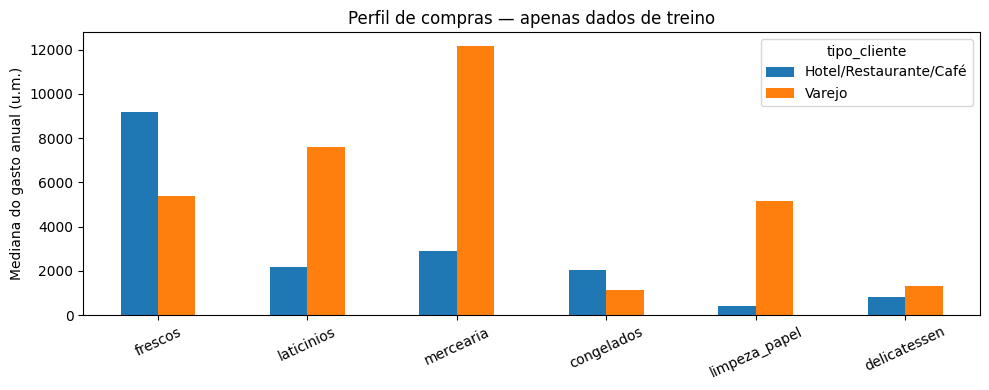

In [3]:
display(X_treino.describe().round(1))
print("Tipos de clientes no treino:")
print(y_treino.value_counts())
perfis = X_treino.assign(tipo_cliente=y_treino).groupby("tipo_cliente").median()
display(perfis.round(0))
perfis.T.plot.bar(figsize=(10, 4), rot=25)
plt.ylabel("Mediana do gasto anual (u.m.)")
plt.title("Perfil de compras — apenas dados de treino")
plt.tight_layout()
plt.show()

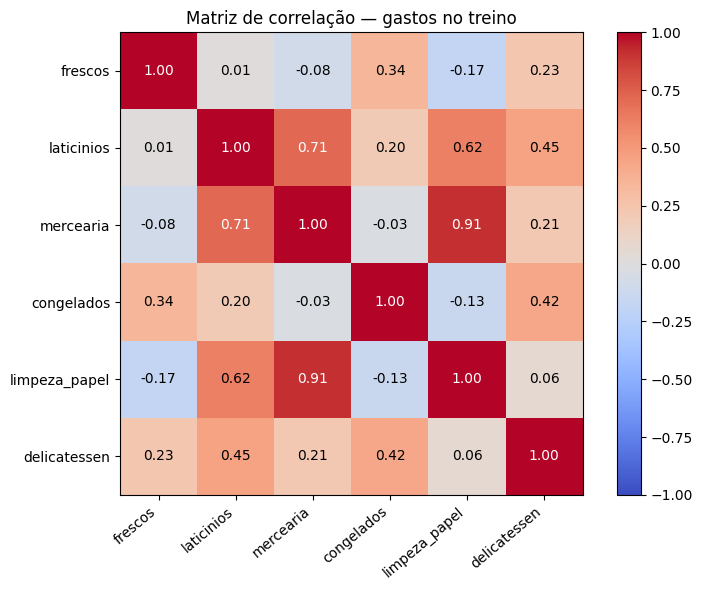

In [4]:
correlacao = X_treino.corr()
fig, ax = plt.subplots(figsize=(8, 6))
imagem = ax.imshow(correlacao, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(colunas)), colunas, rotation=40, ha="right")
ax.set_yticks(range(len(colunas)), colunas)
for i in range(len(colunas)):
    for j in range(len(colunas)):
        valor = correlacao.iloc[i, j]
        ax.text(j, i, f"{valor:.2f}", ha="center", va="center",
                color="white" if abs(valor) > 0.7 else "black")
fig.colorbar(imagem, ax=ax)
ax.set_title("Matriz de correlação — gastos no treino")
plt.tight_layout()
plt.show()

## 4. Primeiro SVM
O SVM aprende uma fronteira que separa os tipos de clientes, buscando uma margem e admitindo violações controladas por C.

**Por que padronizar?** Gastos com amplitudes maiores podem dominar as distâncias. `StandardScaler` ajusta a escala de cada coluna usando média e desvio do treino. No formulário, você continuará informando os gastos originais no formulário; o modelo faz a transformação.

`make_pipeline` liga a padronização ao SVM. O `fit` aprende ambas as etapas apenas no conjunto recebido.

Crie o modelo com `StandardScaler` e `SVC(C=1, kernel="rbf", gamma="scale")`. Treine com `fit` usando apenas o treino, classifique a validação com `predict` e calcule a acurácia: a proporção de previsões corretas.

In [9]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

modelo = make_pipeline(StandardScaler(), SVC(C=1, kernel="rbf", gamma="scale"))

modelo.fit(X_treino, y_treino)
previsoes = modelo.predict(X_validacao)

print(f"Acurácia na validaçao: {accuracy_score(y_validacao, previsoes):.1%}")

Acurácia na validaçao: 89.8%


## 5. Os três hiperparâmetros
**Parâmetros** são aprendidos no treinamento. **Hiperparâmetros** são configurações que escolhemos antes de treinar.

| Configuração | Ideia principal | O que investigar |
|---|---|---|
| C | Penalização das violações da margem | C pequeno regulariza mais; C grande pode ajustar demais |
| kernel | Forma de construir a separação | `linear` para fronteira linear; `rbf` permite fronteiras curvas |
| gamma | No RBF, alcance da influência dos exemplos | Alto: influência mais localizada; baixo: mais ampla |

`gamma="scale"` calcula um valor a partir dos dados recebidos pelo SVM. `gamma` não afeta o kernel linear.

**Maior não significa melhor.** Compare treino e validação. Um resultado muito alto no treino e pior na validação pode indicar sobreajuste.

## 6. Comparar configurações
Mudamos uma configuração por vez em relação à referência. Os dados e a padronização permanecem iguais. O critério de escolha é a acurácia da validação; no empate, escolhemos a primeira linha. A matriz de confusão permitirá verificar os erros de cada classe.

Para cada configuração, treine um modelo apenas com o conjunto de treino e registre a acurácia nos dois conjuntos. Compare as barras do gráfico e identifique qual configuração teve o melhor resultado na validação.

,Configuração,Treino (%),Validação (%)
0,Referência,92.9,89.8
1,C pequeno,67.6,68.2
2,C grande,95.7,86.4
3,Gamma baixo,75.6,78.4
4,Gamma alto,100.0,68.2
5,Linear,91.5,92.0
6,hugo,92.9,89.8
7,opa,91.8,93.2


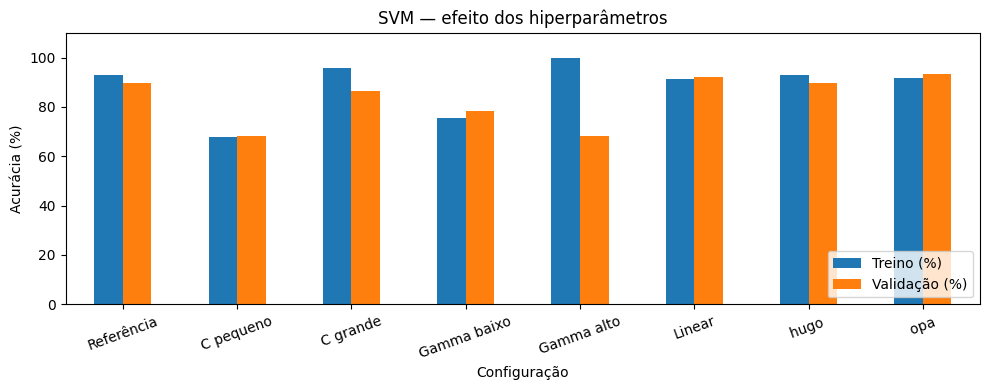

In [72]:
configuracoes = [
  {"nome": "Referência", "C": 1, "kernel": "rbf", "gamma": "scale"},
  {"nome": "C pequeno", "C": 0.01, "kernel": "rbf", "gamma": "scale"},
  {"nome": "C grande", "C": 100, "kernel": "rbf", "gamma": "scale"},
  {"nome": "Gamma baixo", "C": 1, "kernel": "rbf", "gamma": 0.001},
  {"nome": "Gamma alto", "C": 1, "kernel": "rbf", "gamma": 100},
  {"nome": "Linear", "C": 1, "kernel": "linear", "gamma": "scale"},

  # {"nome": "hugo ", "C": 1.2, "kernel": "rbf", "gamma": "scale"},
  # {"nome": " opa ", "C": 100, "kernel": "rbf", "gamma": 0.002},
]
resultados = []
modelos = []  # Guarde os modelos treinados na mesma ordem das configurações.
for config in configuracoes:
    candidato = make_pipeline(StandardScaler(), SVC(
        C=config["C"], kernel=config["kernel"], gamma=config["gamma"]
    ))
    candidato.fit(X_treino, y_treino)
    modelos.append(candidato)
    resultados.append({
        "Configuração": config["nome"],
        "Treino (%)": 100 * candidato.score(X_treino, y_treino),
        "Validação (%)": 100 * candidato.score(X_validacao, y_validacao)
    })
comparacao = pd.DataFrame(resultados)
display(comparacao.round(1))
comparacao.set_index("Configuração").plot.bar(figsize=(10, 4), rot=20)
plt.ylim(0, 110)
plt.ylabel("Acurácia (%)")
plt.title("SVM — efeito dos hiperparâmetros")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 7. Selecionar o modelo e analisar a validação
Selecione a configuração com maior acurácia na validação. Em caso de empate, use a primeira configuração da lista. Recupere o modelo já treinado correspondente para analisar suas previsões e utilizá-lo no formulário.

Compare com uma referência simples: um classificador que sempre responde o tipo de cliente mais frequente no treino. Depois, construa a matriz de confusão para identificar quais classes o SVM confundiu.

**Como interpretar o resultado:** esta é a mesma validação utilizada na escolha dos hiperparâmetros. Portanto, o resultado é exploratório e pode ser otimista; não representa uma avaliação final independente. Em um projeto completo, um terceiro conjunto, chamado **teste**, seria reservado para avaliar o modelo depois de todas as escolhas.

O modelo usado no formulário permanecerá treinado apenas nos 80% de treino.

Configuração escolhida: {'nome': 'Linear', 'C': 1, 'kernel': 'linear', 'gamma': 'scale'}
Referência na validação: 68.2%
SVM na validação: 92.0%
Resultado exploratório: esta validação também foi usada para escolher o modelo.


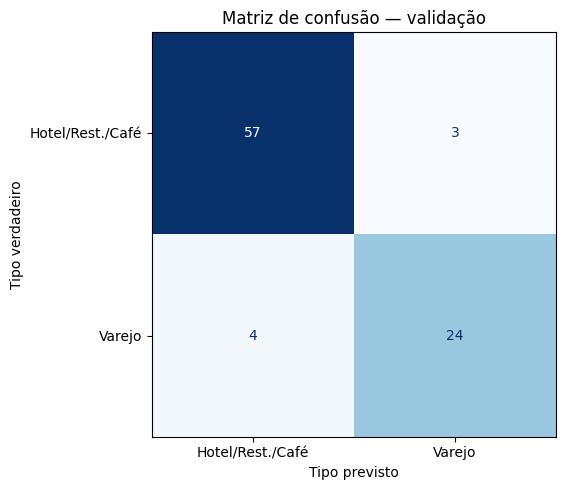

In [15]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import ConfusionMatrixDisplay

# Escolha pela validação e recupere o modelo já treinado na etapa anterior.
indice = comparacao["Validação (%)"].idxmax()
escolhida = configuracoes[indice]
modelo_escolhido = modelos[indice]
print("Configuração escolhida:", escolhida)
pred_validacao = modelo_escolhido.predict(X_validacao)

# Aprenda a classe mais frequente apenas a partir do treino.
referencia = DummyClassifier(strategy="most_frequent")
referencia.fit(X_treino, y_treino)
print(f"Referência na validação: {referencia.score(X_validacao, y_validacao):.1%}")
print(f"SVM na validação: {accuracy_score(y_validacao, pred_validacao):.1%}")
print("Resultado exploratório: esta validação também foi usada para escolher o modelo.")

classes = ["Hotel/Restaurante/Café", "Varejo"]
fig, ax = plt.subplots(figsize=(7, 5))
ConfusionMatrixDisplay.from_predictions(
    y_validacao, pred_validacao, labels=classes,
    display_labels=["Hotel/Rest./Café", "Varejo"],
    cmap="Blues", colorbar=False, ax=ax
)
ax.set_xlabel("Tipo previsto")
ax.set_ylabel("Tipo verdadeiro")
ax.set_title("Matriz de confusão — validação")
plt.tight_layout()
plt.show()

### Interpretar os erros
A diagonal da matriz contém os acertos. Os demais valores mostram os clientes confundidos. Um varejista pode comprar de forma parecida com um restaurante; as compras não determinam com certeza o tipo de estabelecimento.

Na aplicação sugerida, a previsão seria uma sugestão para revisão, não uma alteração automática de cadastro.

Leia cada linha como a classe verdadeira e cada coluna como a classe prevista. Conte os erros de cada tipo e examine alguns clientes classificados incorretamente na tabela abaixo.

In [16]:
analise = X_validacao.copy()
analise["Tipo verdadeiro"] = y_validacao
analise["Tipo previsto"] = pred_validacao
erros = analise[analise["Tipo verdadeiro"] != analise["Tipo previsto"]]
print("Clientes classificados incorretamente:", len(erros), "de", len(X_validacao))
display(erros.head())

Clientes classificados incorretamente: 7 de 88


,frescos,laticinios,mercearia,congelados,limpeza_papel,delicatessen,Tipo verdadeiro,Tipo previsto
281,12238,7108,6235,1093,2328,2079,Varejo,Hotel/Restaurante/Café
426,13134,9347,14316,3141,5079,1894,Hotel/Restaurante/Café,Varejo
182,694,8533,10518,443,6907,156,Hotel/Restaurante/Café,Varejo
334,16823,928,2743,11559,332,3486,Varejo,Hotel/Restaurante/Café
181,112151,29627,18148,16745,4948,8550,Hotel/Restaurante/Café,Varejo


## 8. Formulário — classificar outro perfil de compras
Informe **gastos anuais em u.m.**, não quantidades nem gastos mensais. Os botões carregam medianas de cada classe calculadas **apenas no treino**, como perfis ilustrativos: não são clientes reais nem têm classificação garantida.

Comece pelos exemplos e depois altere uma categoria por vez. Uma mudança de previsão significa que o perfil cruzou a fronteira do modelo; não significa que o cliente realmente mudou de atividade.

Evite valores muito diferentes dos exemplos do treino. O modelo sempre escolhe entre duas classes, mesmo quando o perfil não se parece com nenhum cliente conhecido.

In [18]:
import ipywidgets as widgets
from google.colab import output
output.enable_custom_widget_manager()

rotulos = ["Frescos", "Laticínios", "Mercearia", "Congelados", "Limpeza/papel", "Delicatessen"]
campos = {
    coluna: widgets.BoundedFloatText(
        value=float(X_treino[coluna].median()), min=0,
        max=1000000, step=100, description=rotulo + ":",
        style={"description_width": "120px"}, layout=widgets.Layout(width="340px")
    ) for coluna, rotulo in zip(colunas, rotulos)
}
exemplo_hotel = widgets.Button(description="Exemplo hotel/restaurante", layout=widgets.Layout(width="220px"))
exemplo_varejo = widgets.Button(description="Exemplo varejo")
botao = widgets.Button(description="Classificar cliente", button_style="primary")
saida = widgets.Output()

def carregar_perfil(tipo):
    for coluna in colunas:
        campos[coluna].value = float(perfis.loc[tipo, coluna])
    with saida:
        saida.clear_output()
        print("Perfil carregado. Clique em Classificar cliente.")

exemplo_hotel.on_click(lambda _: carregar_perfil("Hotel/Restaurante/Café"))
exemplo_varejo.on_click(lambda _: carregar_perfil("Varejo"))

def classificar(_):
    novo = pd.DataFrame([{coluna: campo.value for coluna, campo in campos.items()}])
    with saida:
        saida.clear_output()
        print("Tipo sugerido pelo modelo:", modelo_escolhido.predict(novo)[0])
        print("Sugestão experimental baseada no perfil de compras, sujeita a erros.")

botao.on_click(classificar)
display(widgets.VBox(list(campos.values())), widgets.HBox([exemplo_hotel, exemplo_varejo]), botao, saida)

Button(button_style='primary', description='Classificar cliente', style=ButtonStyle())

Output()

## 9. Fontes
- [Kaggle — Wholesale Customers](https://www.kaggle.com/datasets/binovi/wholesale-customers-data-set)
- [UCI — documentação, unidades e licença](https://archive.ics.uci.edu/dataset/292/wholesale+customers)
- [SVC — documentação](https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVC.html)
- [StandardScaler — documentação](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html)
